# IBM Quantum & Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 3: Can You Change the Correlation?

---

### **Problem Statement**
Two qubits can be prepared in a state where their measurement outcomes are strongly correlated. Your task is to modify a two-qubit circuit and investigate whether you can change the relationship between the two measurement outcomes.

### **Design Constraints**
- Use exactly **2 qubits**.
- **Measure both qubits**.
- Start from the **Bell-state circuit** demonstrated during the workshop.
- **Add or modify only one quantum gate**.
- Use **no more than 4 quantum gates** before measurement.
- Be created and executed using **Qiskit**.
- Use **100 shots**.


## Step 1: Environment Setup and Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

backend = AerSimulator()
SHOTS = 100
print(f"AerSimulator backend ready. Shots: {SHOTS}")


AerSimulator backend ready. Shots: 100


## Step 2: Original Circuit — Standard Bell State ($|\Phi^+\rangle$)

### **Think Before You Run (Prediction for Original Circuit)**
- **Starting State**: Both qubits start in $|00\rangle$.
- **Circuit Construction**:
  1. Apply an $H$ gate to qubit 0: $|+\rangle|0\rangle = \frac{|00\rangle + |10\rangle}{\sqrt{2}}$.
  2. Apply a CNOT ($CX$) gate with control qubit 0 and target qubit 1:
     $$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$
- **Predicted Outcomes**:
  - Out of the four possible computational basis outcomes (`00`, `01`, `10`, `11`), only **`00`** and **`11`** have non-zero amplitudes.
  - The two qubits are **maximally correlated (identical outcomes)**: if qubit 0 is measured as `0`, qubit 1 is always `0`; if qubit 0 is measured as `1`, qubit 1 is always `1`.
  - Theoretical probabilities: $P(00) = 50\%$, $P(11) = 50\%$, $P(01) = 0\%$, $P(10) = 0\%$.
- **Prediction for 100 Shots**: Approximately **50 counts of `00`** and **50 counts of `11`**. Neither `01` nor `10` should appear.


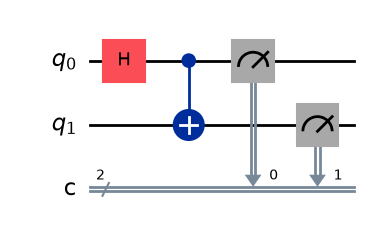

In [2]:
# Create original 2-qubit Bell-state circuit
qc_orig = QuantumCircuit(2, 2)

# Bell state |Phi+>: H gate on q0, CNOT with control q0 and target q1 (2 gates)
qc_orig.h(0)
qc_orig.cx(0, 1)

# Measure both qubits (q0 -> c0, q1 -> c1)
qc_orig.measure([0, 1], [0, 1])

# Draw original circuit
qc_orig.draw('mpl')


Original Bell Circuit Results (100 shots): {'00': 53, '11': 47}


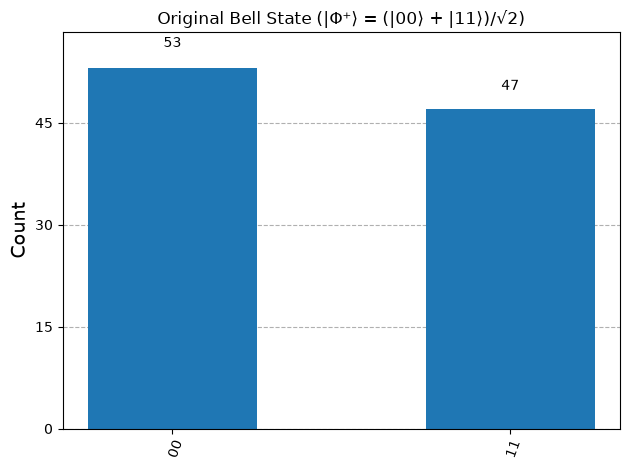

In [3]:
# Execute original circuit for 100 shots
result_orig = backend.run(qc_orig, shots=SHOTS).result()
counts_orig = result_orig.get_counts()

print("Original Bell Circuit Results (100 shots):", counts_orig)

# Display histogram
plot_histogram(counts_orig, title="Original Bell State (|Φ⁺⟩ = (|00⟩ + |11⟩)/√2)")


## Step 3: Modified Circuit — Changing the Correlation ($|\Psi^+\rangle$)

### **Modification Strategy**
- To change the correlation between the two qubits, we add **only one quantum gate**: an **$X$ (bit-flip) gate** on qubit 1 after the CNOT gate.
- Gate count before measurement: $H(0) + CX(0,1) + X(1) = 3$ quantum gates (satisfying the constraint $\le 4$ quantum gates).

### **Think Before You Run (Prediction for Modified Circuit)**
- **State Evolution**:
  $$|00\rangle \xrightarrow{H_0} \frac{|0\rangle+|1\rangle}{\sqrt{2}}|0\rangle \xrightarrow{CX_{0,1}} \frac{|00\rangle+|11\rangle}{\sqrt{2}} \xrightarrow{X_1} \frac{|01\rangle+|10\rangle}{\sqrt{2}} = |\Psi^+\rangle$$
- **Which outcomes do you expect?**
  - The outcomes **`01`** and **`10`** will dominate completely!
- **Will the two qubits still produce the same outcomes?**
  - **No.** The two qubits are now **anti-correlated (opposite outcomes)**. Whenever qubit 0 is `0`, qubit 1 is `1`; whenever qubit 0 is `1`, qubit 1 is `0`.
- **Will 00 and 11 dominate? Could 01 and 10 become more frequent?**
  - Outcomes `00` and `11` will drop to **0%**.
  - Outcomes `01` and `10` will become **100%** of the observed measurements (~50% each).
- **Prediction for 100 Shots**: Approximately **50 counts of `01`** and **50 counts of `10`**.


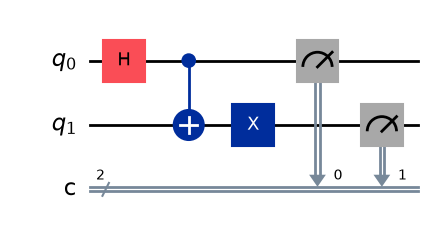

In [4]:
# Create modified circuit with exactly ONE added gate
qc_mod = QuantumCircuit(2, 2)

# Start from Bell state
qc_mod.h(0)
qc_mod.cx(0, 1)

# Add exactly ONE gate: X gate on qubit 1 (total 3 gates <= 4)
qc_mod.x(1)

# Measure both qubits
qc_mod.measure([0, 1], [0, 1])

# Draw modified circuit
qc_mod.draw('mpl')


Modified Circuit Results (100 shots): {'10': 46, '01': 54}


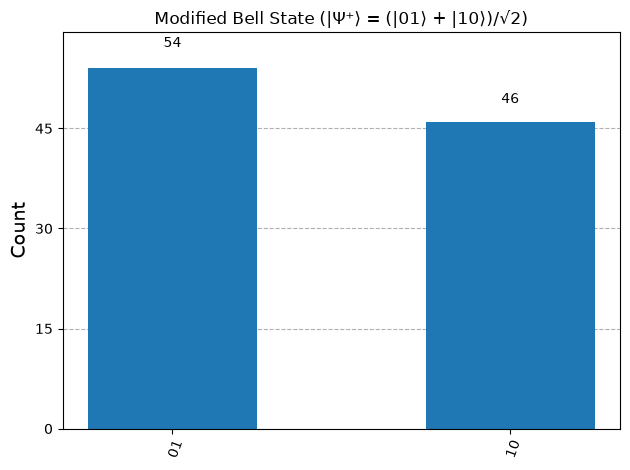

In [5]:
# Execute modified circuit for 100 shots
result_mod = backend.run(qc_mod, shots=SHOTS).result()
counts_mod = result_mod.get_counts()

print("Modified Circuit Results (100 shots):", counts_mod)

# Display histogram
plot_histogram(counts_mod, title="Modified Bell State (|Ψ⁺⟩ = (|01⟩ + |10⟩)/√2)")


## Step 4: Comparison of Original vs Modified Circuit

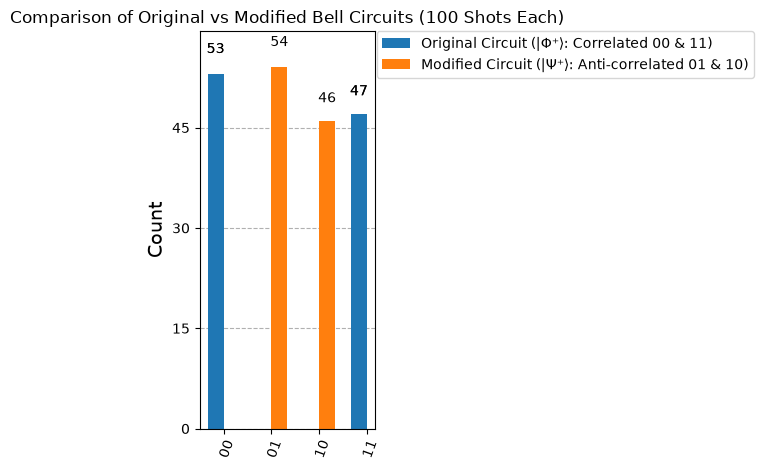

In [6]:
# Side-by-side histogram comparison
plot_histogram(
    [counts_orig, counts_mod],
    legend=['Original Circuit (|Φ⁺⟩: Correlated 00 & 11)', 'Modified Circuit (|Ψ⁺⟩: Anti-correlated 01 & 10)'],
    title='Comparison of Original vs Modified Bell Circuits (100 Shots Each)'
)


## Step 5: Detailed Explanation of Observed Changes

### **1. How the Modification Changed the Measurement Outcomes:**
In the original circuit, the entanglement produced the Bell state:
$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$
Here, both qubits are positively correlated; measuring one qubit immediately determines that the other qubit has the **exact same** state ($0 \rightarrow 0$, $1 \rightarrow 1$).

By adding a single Pauli-$X$ gate to qubit 1, we applied the transformation $X|0\rangle = |1\rangle$ and $X|1\rangle = |0\rangle$ exclusively to the second qubit:
$$X_1 |\Phi^+\rangle = X_1 \left(\frac{|00\rangle + |11\rangle}{\sqrt{2}}\right) = \frac{|01\rangle + |10\rangle}{\sqrt{2}} = |\Psi^+\rangle$$
This completely flipped the second qubit's measurement value conditional on the entangled superposition, transforming the positive correlation ($00, 11$) into an **anti-correlation ($01, 10$)**.

### **2. Answers to "Think Before You Run" Questions:**
- **Which outcomes do you expect?**  
  Outcomes `01` and `10` with equal 50% theoretical probability each.
- **Will the two qubits still produce the same outcomes?**  
  No. They now always produce **opposite outcomes**.
- **Will 00 and 11 dominate? Could 01 and 10 become more frequent?**  
  `00` and `11` no longer appear at all. `01` and `10` now account for 100% of the distribution.
